# Vehicle Localization Basics

This notebook introduces the basic concepts required for vehicle localization.

The experiment focuses on:

- Coordinate frames
- Vehicle pose representation
- Position and heading
- Coordinate transformation
- Simulated sensor measurements
- Basic position estimation
- Localization error evaluation

The example uses a simplified two-dimensional vehicle model.

In [2]:
# 1-12D — Environment and Library Setup

import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)

NumPy version: 2.4.6


## Coordinate Frames

Vehicle localization requires a consistent reference frame.

Two frames are used in this simplified example:

- **World frame:** fixed reference frame in which the vehicle position is expressed.
- **Vehicle frame:** coordinate frame attached to the vehicle.

The world frame uses:

- x-axis: longitudinal world direction
- y-axis: lateral world direction

The vehicle pose in the world frame is represented by:

`[x, y, theta]`

where:

- `x` = vehicle x-position
- `y` = vehicle y-position
- `theta` = vehicle heading

In [3]:
# 2-12D — Define Vehicle Pose in the World Frame

vehicle_pose = np.array([
    10.0,                 # x position [m]
    5.0,                  # y position [m]
    np.deg2rad(30.0)      # heading [rad]
])

x, y, theta = vehicle_pose

print(f"x position: {x:.2f} m")
print(f"y position: {y:.2f} m")
print(f"heading: {np.rad2deg(theta):.2f} deg")

x position: 10.00 m
y position: 5.00 m
heading: 30.00 deg


## Vehicle Pose Representation

A vehicle pose describes both its location and orientation.

For a planar vehicle:

`pose = [x, y, theta]`

The position is given by `(x, y)`, while `theta` describes the
vehicle heading relative to the world x-axis.

The position alone is therefore not sufficient to completely describe
the vehicle state in a two-dimensional environment.

In [4]:
# 3-12D — Extract Position and Heading from Vehicle Pose

position = vehicle_pose[:2]
heading = vehicle_pose[2]

print("Position:", position)
print("Heading [rad]:", heading)
print("Heading [deg]:", np.rad2deg(heading))

Position: [10.  5.]
Heading [rad]: 0.5235987755982988
Heading [deg]: 29.999999999999996


## Coordinate Transformation

A point expressed in the vehicle frame can be transformed into the
world frame using the vehicle pose.

For a 2D rotation:

`R(theta) = [[cos(theta), -sin(theta)],`
`            [sin(theta),  cos(theta)]]`

The world-frame point is then:

`p_world = R(theta) @ p_vehicle + [x, y]`

This transformation combines the vehicle's orientation and position.

In [5]:
# 4-12D — Transform a Point from Vehicle Frame to World Frame

def vehicle_to_world(point_vehicle, pose):
    x, y, theta = pose

    rotation = np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta),  np.cos(theta)]
    ])

    position_world = np.array([x, y])

    return rotation @ point_vehicle + position_world


point_vehicle = np.array([2.0, 0.0])

point_world = vehicle_to_world(point_vehicle, vehicle_pose)

print("Vehicle-frame point:", point_vehicle)
print("World-frame point:", point_world)

Vehicle-frame point: [2. 0.]
World-frame point: [11.73205081  6.        ]


## Simulated Vehicle Motion

A simplified vehicle trajectory is generated to represent the vehicle's
reference motion in the world frame.

The vehicle is assumed to move with a known forward speed while its
heading changes gradually.

The reference trajectory provides the position against which the
localization estimate can be evaluated.

In [12]:
# 5-12D — Generate Reference Vehicle Motion

num_steps = 50
dt = 1.0

time = np.arange(num_steps) * dt

speed = 0.5
true_theta = 0.08 * time

true_x = np.zeros(num_steps)
true_y = np.zeros(num_steps)

for k in range(1, num_steps):
    true_x[k] = true_x[k - 1] + speed * np.cos(true_theta[k - 1]) * dt
    true_y[k] = true_y[k - 1] + speed * np.sin(true_theta[k - 1]) * dt

true_positions = np.column_stack((true_x, true_y))

print("Number of trajectory points:", len(true_positions))
print("Initial position:", true_positions[0])
print("Final position:", true_positions[-1])

Number of trajectory points: 50
Initial position: [0. 0.]
Final position: [-3.95806539 10.87003367]


## Simulated Position Measurements

A localization sensor does not provide perfectly accurate position
measurements.

Measurement noise is therefore added to the reference vehicle position
to simulate imperfect sensor observations.

The noisy measurements represent the sensor input available to the
localization process.

In [18]:
# 6-12D — Generate Noisy Sensor Measurements

rng = np.random.default_rng(42)

position_noise_std = 0.5
speed_noise_std = 0.03
heading_noise_std = np.deg2rad(1.0)

# Noisy position measurements from a position sensor
measured_x = true_x + rng.normal(
    0.0,
    position_noise_std,
    num_steps
)

measured_y = true_y + rng.normal(
    0.0,
    position_noise_std,
    num_steps
)

measured_positions = np.column_stack((measured_x, measured_y))

# Noisy motion measurements used for dead reckoning
measured_speed = speed + rng.normal(
    0.0,
    speed_noise_std,
    num_steps
)

measured_heading = true_theta + rng.normal(
    0.0,
    heading_noise_std,
    num_steps
)

print("Position measurement noise:", position_noise_std, "m")
print("Speed measurement noise:", speed_noise_std, "m/s")
print("Heading measurement noise:", np.rad2deg(heading_noise_std), "deg")
print("First measured speed:", measured_speed[0])
print("First measured heading:", np.rad2deg(measured_heading[0]), "deg")

Position measurement noise: 0.5 m
Speed measurement noise: 0.03 m/s
Heading measurement noise: 1.0 deg
First measured speed: 0.48865512337881833
First measured heading: -0.1586348370386883 deg


## Motion-Based Position Estimation

A simple dead-reckoning estimate is generated from the assumed vehicle
speed and heading.

Starting from the initial position, the vehicle displacement during
each time step is calculated as:

`dx = v * cos(theta) * dt`

`dy = v * sin(theta) * dt`

The position is then propagated using:

`x_k = x_(k-1) + dx`

`y_k = y_(k-1) + dy`

This represents a simplified motion-based localization estimate.

In [19]:
# 7-12D — Estimate Vehicle Position Using Noisy Dead Reckoning

estimated_x = np.zeros(num_steps)
estimated_y = np.zeros(num_steps)

# Initialize the estimate using the first position measurement
estimated_x[0] = measured_x[0]
estimated_y[0] = measured_y[0]

for k in range(1, num_steps):
    dx = measured_speed[k - 1] * np.cos(measured_heading[k - 1]) * dt
    dy = measured_speed[k - 1] * np.sin(measured_heading[k - 1]) * dt

    estimated_x[k] = estimated_x[k - 1] + dx
    estimated_y[k] = estimated_y[k - 1] + dy

estimated_positions = np.column_stack((estimated_x, estimated_y))

print("Final true position:", true_positions[-1])
print("Final measured position:", measured_positions[-1])
print("Final estimated position:", estimated_positions[-1])

Final true position: [-3.95806539 10.87003367]
Final measured position: [-3.92427585 10.41729414]
Final estimated position: [-3.85258309 10.92280483]


## Localization Error

The Euclidean position error is calculated as the distance between the
estimated vehicle position and the reference position.

`error = sqrt((x_est - x_true)^2 + (y_est - y_true)^2)`

The mean and final position errors are used to quantify the localization
performance of the simplified motion-based estimate.

In [20]:
# 8-12D — Calculate Localization Position Error

position_errors = np.linalg.norm(
    estimated_positions - true_positions,
    axis=1
)

mean_position_error = np.mean(position_errors)
final_position_error = position_errors[-1]

print(f"Mean position error: {mean_position_error:.3f} m")
print(f"Final position error: {final_position_error:.3f} m")

Mean position error: 0.140 m
Final position error: 0.118 m


## Trajectory Visualization

The reference trajectory, noisy sensor measurements, and motion-based
localization estimate are plotted together.

The visualization shows how the estimated vehicle trajectory compares
with the reference trajectory while the measurements contain noise.

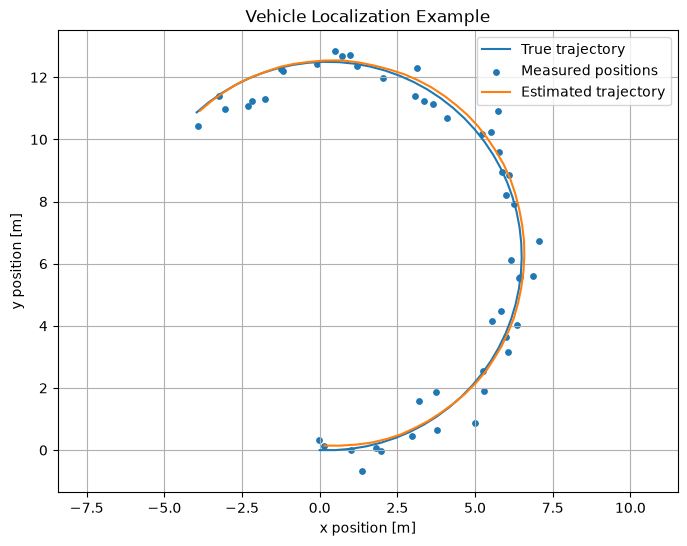

In [21]:
# 9-12D — Visualize Reference, Measurements, and Estimated Trajectory

plt.figure(figsize=(8, 6))

plt.plot(
    true_x,
    true_y,
    label="True trajectory"
)

plt.scatter(
    measured_x,
    measured_y,
    s=15,
    label="Measured positions"
)

plt.plot(
    estimated_x,
    estimated_y,
    label="Estimated trajectory"
)

plt.xlabel("x position [m]")
plt.ylabel("y position [m]")
plt.title("Vehicle Localization Example")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

## Position Error Over Time

The localization error is plotted against time to examine how the
position estimate varies throughout the vehicle trajectory.

The variation in error results from the simulated uncertainty in the
speed and heading measurements used for dead reckoning.

In a practical localization system, sensor bias and accumulated
measurement uncertainty can cause the position error to grow over time.

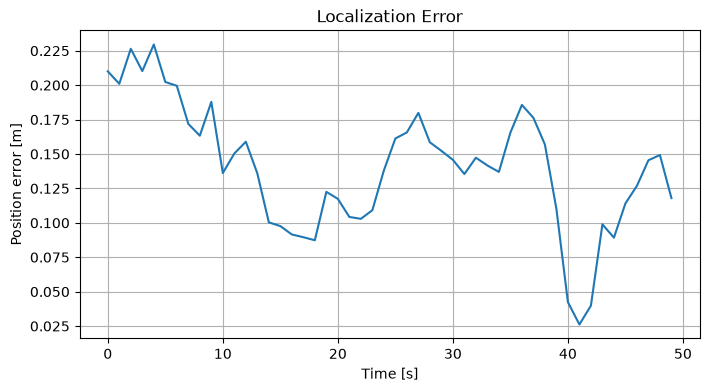

In [22]:
# 10-12D — Visualize Localization Error Over Time

plt.figure(figsize=(8, 4))

plt.plot(
    time,
    position_errors
)

plt.xlabel("Time [s]")
plt.ylabel("Position error [m]")
plt.title("Localization Error")
plt.grid(True)
plt.show()

## Localization Requirements

A practical autonomous vehicle localization system must estimate the
vehicle pose continuously:

`pose = [x, y, theta]`

The required information may come from multiple sensors and vehicle
signals, depending on the localization architecture.

Typical sources include:

- GNSS/GPS
- IMU
- Wheel-speed or wheel-odometry measurements
- Steering information
- Camera or LiDAR observations

The measurements have different characteristics and uncertainties.
Combining them can provide a more robust estimate than relying on a
single measurement source.

## Limitations of the Minimal Experiment

This experiment is intentionally simplified.

It does not implement:

- GPS/IMU sensor fusion
- Wheel odometry
- A full vehicle motion model
- Heading estimation from sensor measurements
- Extended or Unscented Kalman filtering
- SLAM
- Real vehicle sensor data

The cumulative-mean estimator is therefore only a conceptual
demonstration of noisy position measurements and position estimation.

A complete localization system requires a defined motion model,
appropriate sensor models, uncertainty representation, and a suitable
state-estimation or localization algorithm.

## Conclusion

The experiment established the basic representation and requirements
of vehicle localization.

A vehicle pose in a two-dimensional world was represented using
position and heading:

`[x, y, theta]`

Coordinate transformation between the vehicle and world frames was
implemented. Noisy position, speed, and heading measurements were then
used to demonstrate a simplified motion-based dead-reckoning
localization approach.

The final experiment produced:

- Mean position error: `0.140 m`
- Final position error: `0.118 m`

The results show that the estimated trajectory remained close to the
reference trajectory despite the simulated measurement noise.

The experiment also demonstrated that localization depends on both
vehicle motion information and sensor measurements. In a practical
system, sensor uncertainty, bias, and model inaccuracies must be
considered and addressed using appropriate state-estimation and sensor
fusion techniques.

This provides the foundation for more advanced localization and SLAM
methods in the subsequent stages of the project.